# 02 · Baseline: Regressão Logística

Métrica técnica principal: **ROC-AUC**. Métrica de negócio: **custo** (ver `docs/ml_canvas.md`).

In [1]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split

from churn.config import CV_FOLDS, SEED, TEST_SIZE
from churn.data import load_dataset
from churn.evaluate import CV_SCORING
from churn.models import build_pipeline, get_models

In [2]:
X, y = load_dataset()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

In [3]:
baseline = build_pipeline(get_models()['logistic_regression'])
scores = cross_validate(baseline, X_train, y_train, cv=cv, scoring=CV_SCORING)
pd.DataFrame({m: scores[f'test_{m}'] for m in CV_SCORING}).agg(['mean', 'std']).T

,mean,std
roc_auc,0.845994,0.013857
pr_auc,0.660075,0.021874
f1,0.628250,0.025868
recall,0.801338,0.042410
precision,0.516912,0.020898


## Coeficientes (interpretabilidade)

<Axes: >

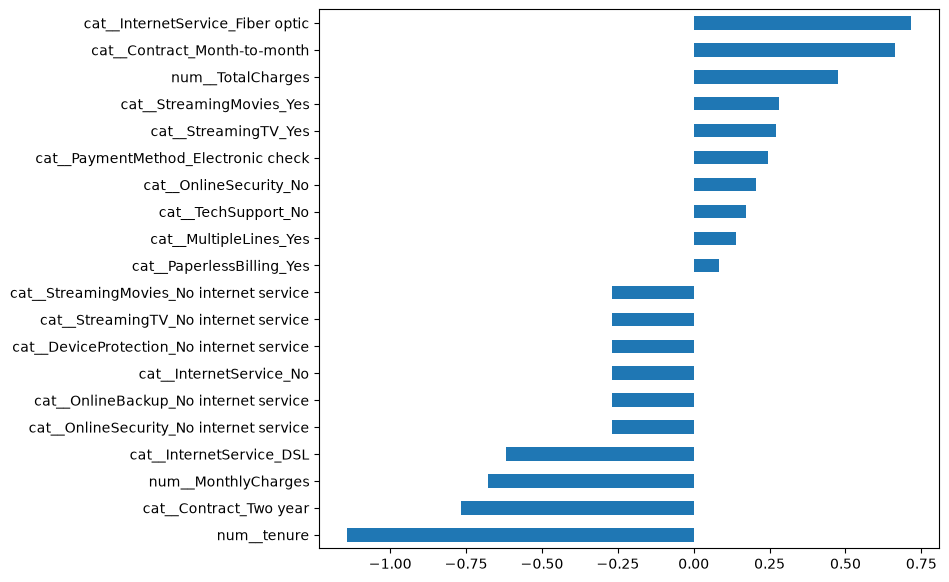

In [4]:
baseline.fit(X_train, y_train)
names = baseline.named_steps['preprocessor'].get_feature_names_out()
coefs = pd.Series(baseline.named_steps['model'].coef_[0], index=names)
coefs.sort_values().iloc[list(range(10)) + list(range(-10, 0))].plot.barh(figsize=(8, 7))

## Conclusões

- **Desempenho do baseline** (CV estratificada de 5 folds no treino, threshold 0,5):
  - ROC-AUC **0,846 ± 0,014**
  - PR-AUC 0,660
  - F1 0,628
  - Recall 0,801
  - Precision 0,517
- **Leitura do resultado:** com `class_weight="balanced"`, o modelo prioriza encontrar quem cancela, e por isso
  o recall é alto à custa da precision. O desvio padrão baixo entre folds indica um resultado estável.
- **Coeficientes:** confirmam o que a EDA mostrou.
  - **Aumentam o risco:** fibra óptica, contrato mensal, streaming e pagamento por electronic check.
  - **Reduzem o risco:** tempo de casa (`tenure`, o efeito mais forte), contrato de 2 anos e internet DSL.
- **Cuidado ao interpretar:** `MonthlyCharges` e `TotalCharges` aparecem com sinais "trocados" porque são
  colineares com `tenure` e com os serviços contratados. Leia os coeficientes como ranking de sinais,
  não como efeito causal isolado.
- **O que esperar dos próximos modelos:** como o baseline linear já captura bem os sinais principais, a
  Random Forest e a MLP devem ganhar pouco em ROC-AUC. O ganho maior tende a vir da escolha do
  **threshold pelo custo de negócio**, e não de um modelo mais complexo.